# Introduction

This project predicts whether a loan application will be approved or not using machine learning. By analyzing applicant details like income, credit history, and education, the model helps automate loan approval decisions and reduce human bias.

# Objectives

Handle missing values and encode categorical features

Build and compare Logistic Regression and Decision Tree models

Address class imbalance using SMOTE

Evaluate models using Precision, Recall, F1-score, and Confusion Matrix

In [48]:
pip install -U scikit-learn imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [49]:
!pip install --upgrade scikit-learn imbalanced-learn

In [50]:
#  Importing All Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from sklearn.preprocessing import LabelEncoder

In [51]:
# Load the dataset
df = pd.read_csv("/kaggle/input/loan-approval-prediction-dataset/loan_approval_dataset.csv")

In [52]:
df.columns = df.columns.str.strip()

In [53]:
print(df.head())

   loan_id  no_of_dependents      education self_employed  income_annum  \
0        1                 2       Graduate            No       9600000   
1        2                 0   Not Graduate           Yes       4100000   
2        3                 3       Graduate            No       9100000   
3        4                 3       Graduate            No       8200000   
4        5                 5   Not Graduate           Yes       9800000   

   loan_amount  loan_term  cibil_score  residential_assets_value  \
0     29900000         12          778                   2400000   
1     12200000          8          417                   2700000   
2     29700000         20          506                   7100000   
3     30700000          8          467                  18200000   
4     24200000         20          382                  12400000   

   commercial_assets_value  luxury_assets_value  bank_asset_value loan_status  
0                 17600000             22700000           80

In [54]:
# Check missing values
print(df.isnull().sum())

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [55]:
# Fill missing values (simple approach)
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

print("\n Missing values handled!")



 Missing values handled!


In [56]:
X = df.drop('loan_status', axis=1)
y = df['loan_status']


In [57]:
print(df.columns)


Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='object')


In [58]:

cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(exclude=['object']).columns


In [59]:
print("\nCategorical Columns:", list(cat_cols))
print("Numerical Columns:", list(num_cols))



Categorical Columns: ['education', 'self_employed']
Numerical Columns: ['loan_id', 'no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [60]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first'), cat_cols)
    ])

In [61]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split complete")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Data split complete
Training samples: 3415
Testing samples: 854


In [62]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Data preprocessing complete!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Data preprocessing complete!
Training shape: (3415, 12)
Testing shape: (854, 12)


# Smote

In [63]:
#  SMOTE to handle class imbalance
sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X_train, y_train)

print("\n SMOTE applied successfully!")
print("Before SMOTE:\n", y_train.value_counts())
print("\nAfter SMOTE:\n", pd.Series(y_resampled).value_counts())


 SMOTE applied successfully!
Before SMOTE:
 loan_status
Approved    2125
Rejected    1290
Name: count, dtype: int64

After SMOTE:
 loan_status
Rejected    2125
Approved    2125
Name: count, dtype: int64


# Logistic Regression

In [64]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_resampled, y_resampled)

# Predictions
y_pred_lr = log_reg.predict(X_test)

# Evaluation
print("Logistic Regression Performance:\n")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))


Logistic Regression Performance:

Accuracy: 0.9320843091334895
              precision    recall  f1-score   support

    Approved       0.95      0.94      0.95       531
    Rejected       0.91      0.91      0.91       323

    accuracy                           0.93       854
   macro avg       0.93      0.93      0.93       854
weighted avg       0.93      0.93      0.93       854



# Decision Tree

In [65]:
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_resampled, y_resampled)

# Predictions
y_pred_dt = dt.predict(X_test)

# Evaluation
print(" Decision Tree Performance:\n")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))


 Decision Tree Performance:

Accuracy: 0.9754098360655737
              precision    recall  f1-score   support

    Approved       0.99      0.97      0.98       531
    Rejected       0.95      0.99      0.97       323

    accuracy                           0.98       854
   macro avg       0.97      0.98      0.97       854
weighted avg       0.98      0.98      0.98       854



# Confusion Matrix

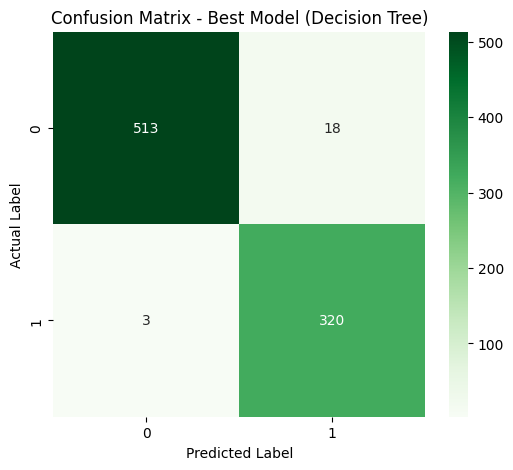

In [66]:
cm_best = confusion_matrix(y_test, y_pred_dt)

# Visualize it
plt.figure(figsize=(6,5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens')
plt.title("Confusion Matrix - Best Model (Decision Tree)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()


# Accuracy comparison

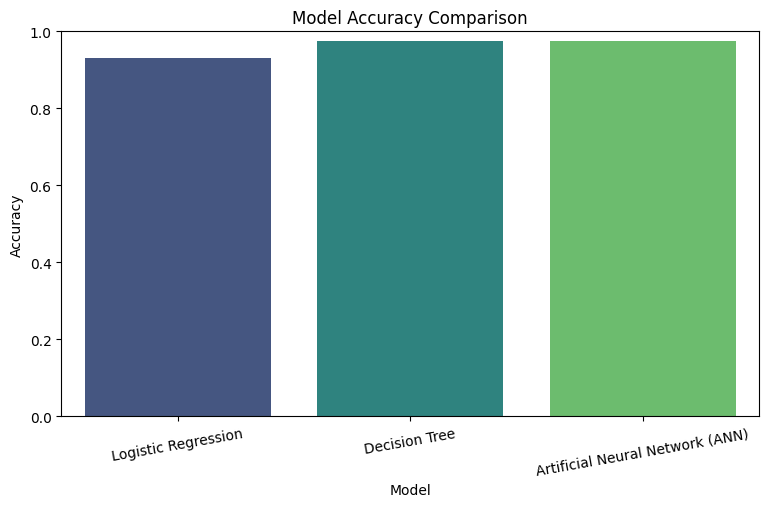

                             Model  Accuracy
0              Logistic Regression  0.932084
1                    Decision Tree  0.975410
2  Artificial Neural Network (ANN)  0.975410


In [74]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Artificial Neural Network (ANN)'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    x='Model',
    y='Accuracy',
    data=results,
    palette='viridis'
)

plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.show()

print(results)


In [68]:

# Artificial Neural Network (ANN) Model

X_dl_train = X_resampled.toarray() if hasattr(X_resampled, "toarray") else np.asarray(X_resampled)
X_dl_test = X_test.toarray() if hasattr(X_test, "toarray") else np.asarray(X_test)

label_encoder = LabelEncoder()
label_encoder.fit(y_train)

y_dl_train = label_encoder.transform(y_resampled)
y_dl_test = label_encoder.transform(y_test)

ann_model = Sequential([
    Input(shape=(X_dl_train.shape[1],)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("ANN model created successfully!")


ANN model created successfully!


In [69]:

# Train the ANN Model

history = ann_model.fit(
    X_dl_train,
    y_dl_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6321 - loss: 0.6133 - val_accuracy: 0.9129 - val_loss: 0.3180
Epoch 2/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8982 - loss: 0.2744 - val_accuracy: 0.9553 - val_loss: 0.1843
Epoch 3/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8943 - loss: 0.2481 - val_accuracy: 0.9329 - val_loss: 0.1983
Epoch 4/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9169 - loss: 0.2056 - val_accuracy: 0.9553 - val_loss: 0.1641
Epoch 5/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9226 - loss: 0.1970 - val_accuracy: 0.9706 - val_loss: 0.1292
Epoch 6/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9201 - loss: 0.1855 - val_accuracy: 0.9518 - val_loss: 0.1599
Epoch 7/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9274 - loss: 0.1680 - val_accuracy: 0.9671 - val_loss: 0.1299
Epoch 8/50
107/107 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9253 - loss: 0.1782 - val_accuracy: 0.

In [73]:

# Evaluate ANN Model on Test Data

loss, accuracy = ann_model.evaluate(
    X_dl_test,
    y_dl_test,
    verbose=0
)

print("ANN Test Accuracy:", accuracy * 100, "%")
print("ANN Test Loss:", loss)


ANN Test Accuracy: 97.54098653793335 %
ANN Test Loss: 0.07995515316724777


In [71]:

# ANN Predictions

y_pred_ann_prob = ann_model.predict(X_dl_test)

y_pred_ann_encoded = (
    y_pred_ann_prob >= 0.5
).astype(int).ravel()

y_pred_ann = label_encoder.inverse_transform(
    y_pred_ann_encoded
)

# Classification Report

print("ANN Classification Report:")
print(classification_report(
    y_test,
    y_pred_ann,
    zero_division=0
))


27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ANN Classification Report:
              precision    recall  f1-score   support

    Approved       0.97      0.99      0.98       531
    Rejected       0.98      0.95      0.97       323

    accuracy                           0.98       854
   macro avg       0.98      0.97      0.97       854
weighted avg       0.98      0.98      0.98       854



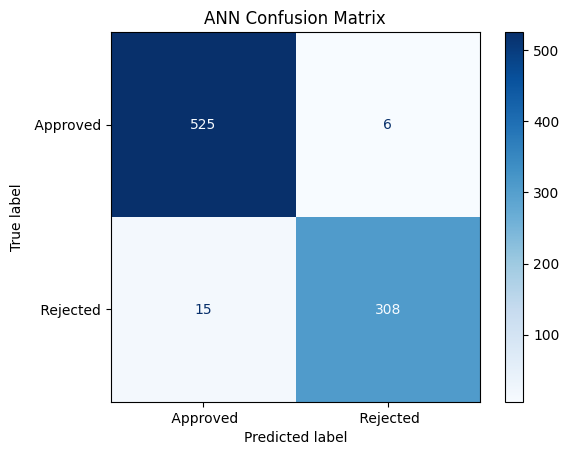

In [72]:

# Confusion Matrix for ANN

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_ann)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap='Blues')
plt.title("ANN Confusion Matrix")
plt.show()


In [75]:
# Save ANN model
ann_model.save("loan_approval_ann.keras")

print("ANN model saved successfully!")

ANN model saved successfully!


In [76]:
import joblib

# Save preprocessor
joblib.dump(preprocessor, "loan_approval_preprocessor.pkl")

# Save label encoder
joblib.dump(label_encoder, "loan_approval_label_encoder.pkl")

print("Preprocessor saved successfully!")
print("Label Encoder saved successfully!")

Preprocessor saved successfully!
Label Encoder saved successfully!


In [77]:
import zipfile
import os

files_to_save = [
    "loan_approval_ann.keras",
    "loan_approval_preprocessor.pkl",
    "loan_approval_label_encoder.pkl"
]

with zipfile.ZipFile(
    "loan_approval_model_files.zip", "w"
) as zipf:

    for file in files_to_save:
        zipf.write(file)

print("All model files added to ZIP successfully!")

All model files added to ZIP successfully!
